# 04 – Final comparison

All four models, evaluated on the same 80 test photos with the same metrics (`src/rasher_inspection/evaluate.py`). This notebook only reads the saved results of notebooks 02 and 03, so it runs in seconds and needs no images or GPU.

| Model | Notebook |
|---|---|
| Always FAIL (trivial baseline) | 02 |
| Colour histogram + logistic regression | 02 |
| MobileNetV2 CNN, 224 px input | 03 |
| MobileNetV2 CNN, 448 px input | 03 |

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

RESULTS_DIR = Path("../results")
with open(RESULTS_DIR / "02_baselines.json") as f:
    results = json.load(f)
with open(RESULTS_DIR / "03_cnn.json") as f:
    results.update(json.load(f))

# Same colour per model as in notebooks 02 and 03.
MODEL_COLOURS = {"Always FAIL": "#c3c2b7", "Colour histogram": "#1baf7a",
                 "CNN 224 px": "#6250d6", "CNN 448 px": "#e87ba4"}
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e", "xtick.color": "#898781", "ytick.color": "#898781",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8, "axes.axisbelow": True,
})
print(list(results))

['Always FAIL', 'Colour histogram', 'CNN 224 px', 'CNN 448 px']


## 1. Results table (test set, 95% confidence intervals)

In [2]:
def fmt(metric):
    lo, hi = metric["ci"]
    return f"{metric['value']:.1%} ({lo:.0%}–{hi:.0%})"

print(f"{'Model':<18}{'Balanced accuracy':>22}{'Defects caught':>22}{'Good trays passed':>22}"
      f"{'Missed':>8}{'Rejected':>10}")
for name, r in results.items():
    t = r["test"]
    print(f"{name:<18}{fmt(t['balanced_accuracy']):>22}{fmt(t['defects_caught']):>22}"
          f"{fmt(t['good_passed']):>22}{t['missed']:>8}{t['rejected']:>10}")
n_fail = results["Always FAIL"]["test"]["caught"]
n_pass = results["Always FAIL"]["test"]["rejected"]
print(f"\n'Missed' = defective trays passed (of {n_fail}); 'Rejected' = good trays failed (of {n_pass}).")

Model                  Balanced accuracy        Defects caught     Good trays passed  Missed  Rejected
Always FAIL              50.0% (50%–50%)     100.0% (95%–100%)         0.0% (0%–24%)       0        12
Colour histogram         69.6% (54%–84%)       80.9% (70%–88%)       58.3% (32%–81%)      13         5
CNN 224 px               85.0% (72%–95%)       86.8% (77%–93%)       83.3% (55%–95%)       9         2
CNN 448 px               84.1% (73%–92%)       76.5% (65%–85%)       91.7% (65%–99%)      16         1

'Missed' = defective trays passed (of 68); 'Rejected' = good trays failed (of 12).


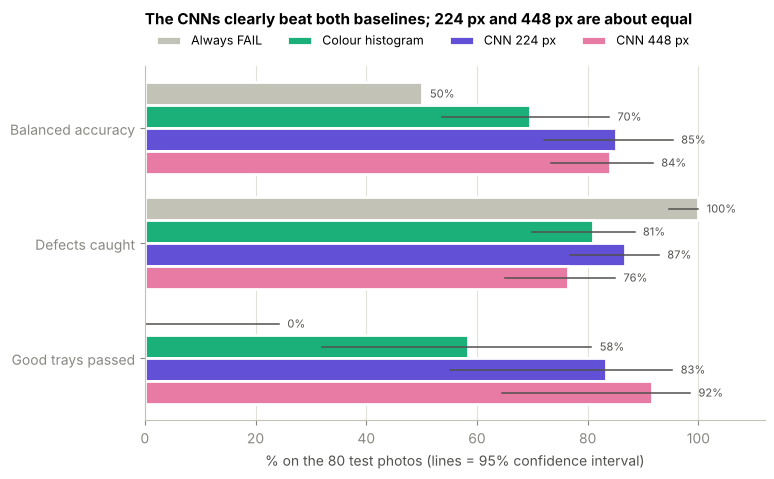

In [3]:
metrics = [("balanced_accuracy", "Balanced accuracy"), ("defects_caught", "Defects caught"),
           ("good_passed", "Good trays passed")]
names = list(results)
height = 0.8 / len(names)

fig, ax = plt.subplots(figsize=(8, 4.6))
for k, name in enumerate(names):
    for m, (key, label) in enumerate(metrics):
        s = results[name]["test"][key]
        lo, hi = s["ci"]
        y = m + (k - (len(names) - 1) / 2) * height
        ax.barh(y, 100 * s["value"], height=height, color=MODEL_COLOURS[name],
                edgecolor="white", linewidth=2, label=name if m == 0 else None)
        ax.plot([100 * lo, 100 * hi], [y, y], color="#52514e", linewidth=1.1)
        ax.text(100 * max(s["value"], hi) + 1.5, y, f"{s['value']:.0%}", va="center", fontsize=8, color="#52514e")
ax.set_yticks(range(len(metrics)), [label for _, label in metrics])
ax.invert_yaxis()
ax.set_xlim(0, 112)
ax.set_xlabel("% on the 80 test photos (lines = 95% confidence interval)")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(0, 1.02), ncol=len(names), fontsize=9)
ax.set_title("The CNNs clearly beat both baselines; 224 px and 448 px are about equal", pad=30)
fig.savefig(RESULTS_DIR / "04_model_comparison.png")
plt.show()

## 2. Where the mistakes are

A confusion matrix counts the four possible outcomes. The two kinds of mistake have different costs: a **missed defect** sends a faulty tray to a customer, a **false reject** wastes a good tray (or sends it for manual re-inspection).

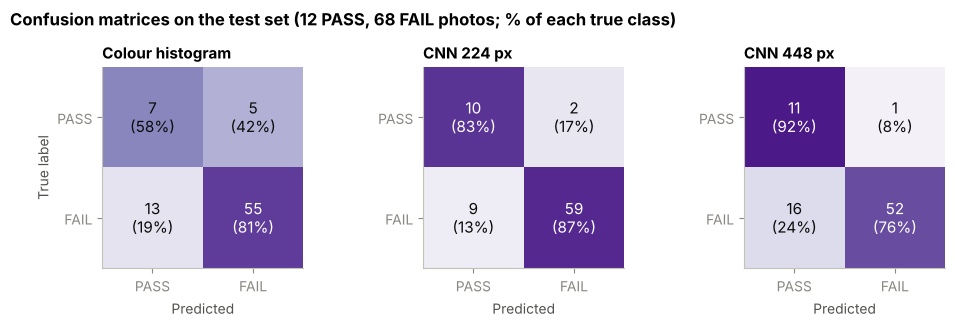

In [4]:
def confusion_matrix(t):
    # rows = true label, columns = predicted label, order (PASS, FAIL)
    return np.array([[t["passed"], t["rejected"]], [t["missed"], t["caught"]]])

shown = ["Colour histogram", "CNN 224 px", "CNN 448 px"]
fig, axes = plt.subplots(1, len(shown), figsize=(10, 3.2))
for ax, name in zip(axes, shown):
    cm = confusion_matrix(results[name]["test"])
    share = cm / cm.sum(axis=1, keepdims=True)   # colour = share of each TRUE class
    ax.imshow(share, cmap="Purples", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]}\n({share[i, j]:.0%})", ha="center", va="center", fontsize=11,
                    color="white" if share[i, j] > 0.6 else "#0b0b0b")
    ax.set_xticks([0, 1], ["PASS", "FAIL"])
    ax.set_yticks([0, 1], ["PASS", "FAIL"])
    ax.set_xlabel("Predicted")
    ax.set_title(name)
    ax.grid(False)
axes[0].set_ylabel("True label")
fig.suptitle("Confusion matrices on the test set (12 PASS, 68 FAIL photos; % of each true class)", x=0.02, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "04_confusion_matrices.png")
plt.show()

## 3. Cost of each model

In [5]:
print(f"{'Model':<18}{'Parameters':>12}{'GFLOPs/photo':>14}{'CPU ms/photo':>14}{'Training':>12}")
print(f"{'Always FAIL':<18}{'0':>12}{'0':>14}{'0':>14}{'none':>12}")
c = results["Colour histogram"]
print(f"{'Colour histogram':<18}{'49':>12}{'~0':>14}{c['ms_per_photo']:>13.1f}*{'< 1 s':>12}")
for name in ("CNN 224 px", "CNN 448 px"):
    r = results[name]
    print(f"{name:<18}{r['parameters']:>12,}{r['gflops_per_photo']:>14.2f}{r['ms_per_photo_cpu']:>14.1f}"
          f"{r['train_minutes']:>9.1f} min")
print("\n* includes loading the JPEG; the CNN times measure the network only (photo already loaded).")

Model               Parameters  GFLOPs/photo  CPU ms/photo    Training
Always FAIL                  0             0             0        none
Colour histogram            49            ~0          3.4*       < 1 s
CNN 224 px           2,226,434          0.47          51.5      4.8 min
CNN 448 px           2,226,434          1.82          74.9     11.8 min

* includes loading the JPEG; the CNN times measure the network only (photo already loaded).


## Conclusions

1. **Accuracy alone is misleading for this data.** "Always FAIL" scores 85% accuracy but 50% balanced accuracy – it never passes a good tray.
2. **Colour alone is a weak signal.** The colour-histogram model beats guessing (69.6% balanced accuracy) but misses 13 of 68 defects and rejects 5 of 12 good trays: defects are about shape and position, which a histogram discards.
3. **The CNN is the clear winner.** At 224 px it reaches 85.0% balanced accuracy, catching 59 of 68 defects and passing 10 of 12 good trays.
4. **Higher resolution did not pay off.** 448 px needs 3.8× the computation and 2.5× the training time, yet its balanced accuracy is the same within the uncertainty, and it missed more defects.
5. **Recommended model: CNN at 224 px.** It is fast enough for a production line even on a CPU (~50 ms per photo, about 20 photos per second).

**Limits of the evidence:** the test set is small (12 PASS photos), so the confidence intervals are wide; each CNN was trained once; all photos come from one camera and belt; and "PASS" means "no defect visible in this photo", not that the whole tray is fine. The model still misses about 1 defect in 8, so in practice it should support human inspectors (e.g. flagging trays for a second look) rather than replace them.